## Data preprocessing

In [6]:
import random
import re
from collections import Counter
 
import numpy as np
from datasets import load_dataset


import matplotlib.pyplot as plt

In [ ]:
SEED = 42
N_FEATURES = 2000
ALPHA = 1.0          # smoothing for the log-count ratio

def load_data(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    raw = load_dataset("stanfordnlp/imdb")

    train_pos, train_neg, test_pos, test_neg = [], [], [], []
    for row in raw["train"]:
        (train_pos if row["label"] == 1 else train_neg).append(row["text"])
    random.shuffle(train_pos)
    random.shuffle(train_neg)
    train_pos, train_neg = train_pos[:2500], train_neg[:2500]

    for row in raw["test"]:
        (test_pos if row["label"] == 1 else test_neg).append(row["text"])
    random.shuffle(test_pos)
    random.shuffle(test_neg)
    test_pos, test_neg = test_pos[:500], test_neg[:500]

    print("train pos:", len(train_pos), "| train neg:", len(train_neg))
    print("test  pos:", len(test_pos), "| test  neg:", len(test_neg))
    return train_pos, train_neg, test_pos, test_neg


def normalize_review(review):
    review = review.replace("<br />", " ").lower()
    review = re.sub(r"[^a-z0-9'!?]", " ", review)   # drop punctuation
    review = re.sub(r"([!?])", r" \1 ", review)      # keep ! and ? as tokens
    return review


# def compute_log_ratios(train_pos, train_neg, features, alpha=ALPHA):
#     idx = {f: j for j, f in enumerate(features)}
#     p = np.full(len(features), alpha, dtype=float)
#     q = np.full(len(features), alpha, dtype=float)

#     for review in train_pos:
#         for word, c in Counter(normalize_review(review).split()).items():
#             j = idx.get(word)
#             if j is not None:
#                 p[j] += c
#     for review in train_neg:
#         for word, c in Counter(normalize_review(review).split()).items():
#             j = idx.get(word)
#             if j is not None:
#                 q[j] += c

#     return np.log((p / p.sum()) / (q / q.sum()))


## Part 3: NB-Weighted Logistic Regression

In [8]:
# 1. Feature Matrix Construction
# Build a feature matrix X of shape (num_documents, 2000).
# Multiply the count of the feature in the document by its Log-Ratio rj to provide the model
# with dense sentiment signals:
# Xi,j = count(featurej in doci) × rj

# 2. Standardization: Standardize your feature matrix (Z-score normalization) and add a Bias column of 1s.

def build_feature_matrix(reviews, feature_list, log_ratios, mean=None, sigma=None):
    idx = {f: j for j, f in enumerate(feature_list)}
    X = np.zeros((len(reviews), len(feature_list)))

    for i, review in enumerate(reviews):
        for word, c in Counter(normalize_review(review).split()).items():
            j = idx.get(word)
            if j is not None:
                X[i, j] = c

    X *= np.asarray(log_ratios)            # X_ij = count * r_j

    if mean is None:                         # fit statistics on TRAIN only
        mean = X.mean(axis=0)
        sigma = X.std(axis=0)
        sigma[sigma == 0] = 1.0            # avoid division by zero

    X = (X - mean) / sigma
    X = np.column_stack([np.ones(len(X)), X])   # bias column
    return X, mean, sigma



In [9]:
# 3. Gradient Descent:
# Implement a Logistic Regression class from scratch.
# Write a training loop using Gradient Descent to minimize Binary Cross-Entropy Loss. Train this model on your standardized X matrix.

class LogisticRegression:

    def __init__(self, lr=0.1, n_iters=1000, l2=0.0, tol=1e-7, verbose=True):
        self.lr = lr              # learning rate (step size)
        self.n_iters = n_iters    # max number of gradient steps
        self.l2 = l2              # L2 strength (0 = no regularization)
        self.tol = tol            # stop if loss improves by less than this
        self.verbose = verbose
        self.w = None
        self.loss_history = []

    # helpers 
    @staticmethod
    def _sigmoid(z):
        # numerically stable: never calls exp on a large positive number
        out = np.empty_like(z, dtype=float)
        # compute sigmoid in two cases: z >= 0 and z < 0
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
        out[~pos] = np.exp(z[~pos]) / (1.0 + np.exp(z[~pos]))
        return out

    # loss = binary cross-entropy + L2 regularization
    def _loss(self, y, p):
        eps = 1e-12                       # avoid log(0)
        # clip predictions to prevent log(0)
        p = np.clip(p, eps, 1 - eps)
        # compute binary cross-entropy loss + L2 regularization
        bce = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        reg = 0.5 * self.l2 * np.sum(self.w[1:] ** 2)   # skip bias
        return bce + reg

    # training 
    def fit(self, X, y):
        n, d = X.shape
        y = np.asarray(y, dtype=float)
        self.w = np.zeros(d)
        self.loss_history = []

        for it in range(self.n_iters):
            p = self._sigmoid(X @ self.w)            # forward pass
            grad = X.T @ (p - y) / n                 # dLoss/dw for BCE
            grad[1:] += self.l2 * self.w[1:]         # L2 term (not on bias)
            self.w -= self.lr * grad                 # gradient descent step

            loss = self._loss(y, self._sigmoid(X @ self.w))
            self.loss_history.append(loss)

            if self.verbose and (it % 100 == 0 or it == self.n_iters - 1):
                acc = np.mean(self.predict(X) == y)
                print(f"iter {it:5d} | loss {loss:.5f} | train acc {acc:.4f}")

            if it > 0 and abs(self.loss_history[-2] - loss) < self.tol:
                if self.verbose:
                    print(f"converged at iter {it}")
                break
        return self

    # inference
    def predict_proba(self, X):
        return self._sigmoid(X @ self.w)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

train pos: 2500 | train neg: 2500
test  pos: 500 | test  neg: 500
most negative words: ['gadget', 'beowulf', 'dillinger', 'dinosaur', 'lousy', 'boll', 'springer', 'nostril', 'picker', 'delia']
most positive words: ['nancy', 'din', 'victoria', 'carla', 'shanghai', 'sissy', 'kriemhild', 'gunga', 'biko', 'bourne']
X_train: (5000, 42586) | X_test: (1000, 42586)
iter     0 | loss 0.44806 | train acc 0.9686
iter   100 | loss 0.02399 | train acc 1.0000
iter   199 | loss 0.01292 | train acc 1.0000

train accuracy: 1.0000
test  accuracy: 0.8400


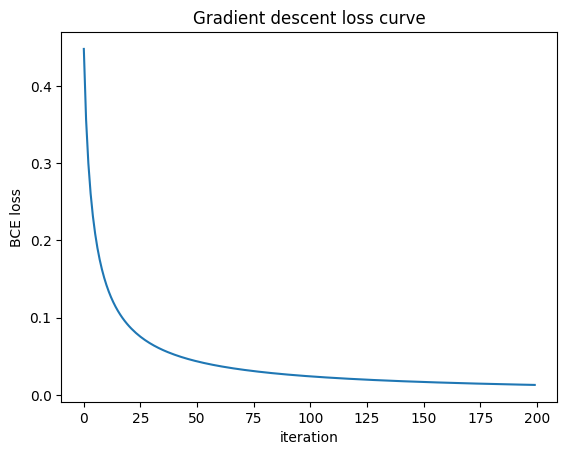

In [10]:
def main():
    # 1. data
    train_pos, train_neg, test_pos, test_neg = load_data()

    # 2. features + log-count ratios (train only)
    features = sorted(set(word for review in train_pos + train_neg
                           for word in normalize_review(review).split()))
    r = compute_log_ratios(train_pos, train_neg, features)
    order = np.argsort(r)
    print("most negative words:", [features[j] for j in order[:10]])
    print("most positive words:", [features[j] for j in order[::-1][:10]])

    # 3. feature matrices (test uses TRAIN mean/std)
    X_train, mu, sigma = build_feature_matrix(train_pos + train_neg, features, r)
    X_test, _, _ = build_feature_matrix(test_pos + test_neg, features, r, mu, sigma)
    y_train = np.array([1] * len(train_pos) + [0] * len(train_neg))
    y_test = np.array([1] * len(test_pos) + [0] * len(test_neg))
    print("X_train:", X_train.shape, "| X_test:", X_test.shape)

    # shuffle training rows (they are currently all-pos then all-neg)
    perm = np.random.RandomState(SEED).permutation(len(y_train))
    X_train, y_train = X_train[perm], y_train[perm]

    # 4. train with gradient descent
    model = LogisticRegression(lr=0.1, n_iters=200, l2=0.0)
    model.fit(X_train, y_train)

    # 5. evaluate
    print(f"\ntrain accuracy: {model.score(X_train, y_train):.4f}")
    print(f"test  accuracy: {model.score(X_test, y_test):.4f}")

    # 6. plot loss curve
    plt.plot(model.loss_history)
    plt.xlabel("iteration")
    plt.ylabel("BCE loss")
    plt.title("Gradient descent loss curve")
    plt.show()

    return model


if __name__ == "__main__":
    main()